# Лабораторная работа № 3. Кластеризация пингвинов архипелага Палмер

## 1. Введение

Цель работы — применить два алгоритма кластеризации к морфометрическим данным, подобрать число кластеров и оценить качество, интерпретируемость и устойчивость полученных групп. Сравниваются **метод K-средних** и **агломеративная кластеризация методом Уорда**. Виды пингвинов используются для внешней проверки готовых разбиений.

Для повторного расчёта откройте ноутбук в Jupyter, выберите ядро Python 3 и выполните все ячейки по порядку. При необходимости установите пакеты командой `%pip install kagglehub numpy pandas scipy scikit-learn matplotlib seaborn threadpoolctl ipywidgets`. Первая ячейка загружает данные через KaggleHub. Если рядом с ноутбуком лежит `penguins_size.csv` из того же датасета, используется этот файл.

## 2. Описание датасета

Набор Palmer Penguins содержит полевые измерения пингвинов трёх видов, собранные в 2007–2009 годах в районе антарктической станции Палмер. В архиве Kaggle есть исходная таблица `penguins_lter.csv` и сокращённая `penguins_size.csv`. В работе используется сокращённая таблица с четырьмя морфометрическими и тремя категориальными признаками. [Датасет на Kaggle](https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data) · [Первичная публикация](https://doi.org/10.1371/journal.pone.0090081)

In [ ]:
%matplotlib inline

from hashlib import sha256
from importlib.metadata import version
from itertools import combinations
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from scipy.spatial.distance import pdist
from scipy.stats import norm, shapiro
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    rand_score,
    silhouette_samples,
    silhouette_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
DATASET_ID = "parulpandey/palmer-archipelago-antarctica-penguin-data"
FEATURES = {
    "culmen_length_mm": "Длина клюва, мм",
    "culmen_depth_mm": "Глубина клюва, мм",
    "flipper_length_mm": "Длина ласта, мм",
    "body_mass_g": "Масса тела, г",
}
SHORT_NAMES = dict(zip(FEATURES, ["Длина\nклюва", "Глубина\nклюва", "Длина\nласта", "Масса\nтела"]))
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.0,
              rc={"grid.color": "#e3e9ef", "axes.titleweight": "bold"})

csv_path = Path("penguins_size.csv")
if not csv_path.is_file():
    dataset_dir = Path(kagglehub.dataset_download(DATASET_ID))
    csv_path = dataset_dir / csv_path.name
    print(f"KaggleHub · каталог версии {dataset_dir.name}")

penguins = pd.read_csv(csv_path)
print(f"{csv_path.name} · {penguins.shape[0]} строк × {penguins.shape[1]} столбцов")
print(f"SHA-256 файла: {sha256(csv_path.read_bytes()).hexdigest()}")
print(" · ".join(f"{pkg} {version(pkg)}" for pkg in ("pandas", "scipy", "scikit-learn", "kagglehub")))

schema = pd.DataFrame({
    "Тип pandas": penguins.dtypes.astype(str),
    "Пропущено (NaN)": penguins.isna().sum(),
    "Уникальных значений": penguins.nunique(),
})
display(schema)
print("Категории пола в исходном файле")
display(penguins["sex"].value_counts(dropna=False).rename("Число записей").to_frame())

KaggleHub · каталог версии 1
penguins_size.csv · 344 строк × 7 столбцов
SHA-256 файла: aa728597b2228a2637e39c6f08e40a80971f4cdac7faf7bc21ff4481ee3e3ae9
pandas 2.2.3 · scipy 1.17.0 · scikit-learn 1.8.0 · kagglehub 1.0.3


,Тип pandas,Пропущено (NaN),Уникальных значений
species,object,0,3
island,object,0,3
culmen_length_mm,float64,2,164
culmen_depth_mm,float64,2,80
flipper_length_mm,float64,2,55
body_mass_g,float64,2,94
sex,object,10,3


Категории пола в исходном файле


,Число записей
sex,
MALE,168
FEMALE,165
NaN,10
.,1


В версии 1 архива **344 строки и 7 столбцов**. В двух строках отсутствуют все четыре измерения. В поле `sex` есть 10 значений `NaN` и одна запись `.`. Признак `island` описывает место отбора, `sex` — пол, а `species` — известный вид. Вход алгоритмов состоит только из длины и глубины клюва, длины ласта и массы тела. Поэтому исследуем группы по строению тела, а `species` подключаем после подбора параметров как внешний эталон. Записи с неизвестным полом пригодны при наличии всех четырёх измерений.

### 2.1. Распределения и одномерные выбросы

На гистограммах пунктиром показана плотность нормального распределения с выборочными средним и стандартным отклонением. Критерий Шапиро–Уилка проверяет нормальность каждой переменной в объединённой выборке. Для поиска крайних значений используются границы Тьюки $Q_1-1{,}5\,IQR$ и $Q_3+1{,}5\,IQR$, где $IQR=Q_3-Q_1$.

Полных морфометрических наблюдений: 342. Исключено строк с пропусками: 2.


,count,mean,std,min,25%,50%,75%,max
"Длина клюва, мм",342.0,43.92,5.46,32.1,39.22,44.45,48.5,59.6
"Глубина клюва, мм",342.0,17.15,1.97,13.1,15.60,17.30,18.7,21.5
"Длина ласта, мм",342.0,200.92,14.06,172.0,190.00,197.00,213.0,231.0
"Масса тела, г",342.0,4201.75,801.95,2700.0,3550.00,4050.00,4750.0,6300.0


,Асимметрия,Нижняя граница Тьюки,Верхняя граница Тьюки,За границами,p (Шапиро–Уилк)
"Длина клюва, мм",0.053,25.31,62.41,0,1.12e-05
"Глубина клюва, мм",-0.143,10.95,23.35,0,4.42e-06
"Длина ласта, мм",0.346,155.50,247.50,0,3.54e-09
"Масса тела, г",0.470,1750.00,6550.00,0,3.68e-08


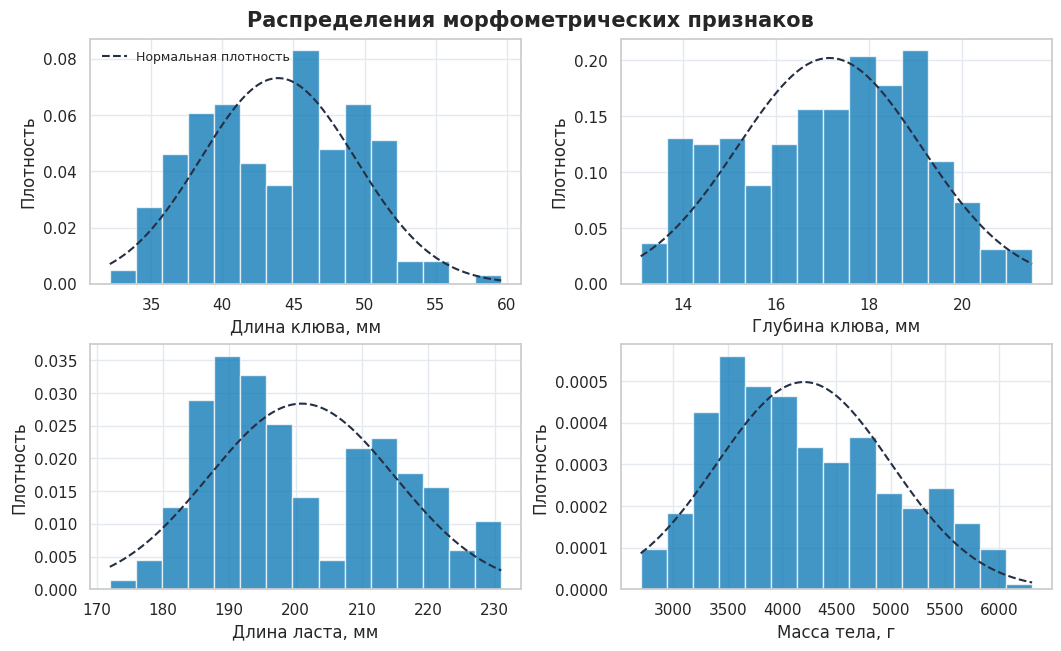

In [ ]:
morphology = penguins.loc[:, list(FEATURES)].dropna()
print(f"Полных морфометрических наблюдений: {len(morphology)}. "
      f"Исключено строк с пропусками: {len(penguins) - len(morphology)}.")
display(morphology.rename(columns=FEATURES).describe().T.round(2))

q1, q3 = morphology.quantile(0.25), morphology.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outside_fences = (morphology.lt(lower) | morphology.gt(upper)).sum()
normality = pd.DataFrame(index=morphology.columns)
normality["Асимметрия"] = morphology.skew().round(3)
normality["Нижняя граница Тьюки"] = lower.round(2)
normality["Верхняя граница Тьюки"] = upper.round(2)
normality["За границами"] = outside_fences
normality["p (Шапиро–Уилк)"] = [f"{shapiro(morphology[name]).pvalue:.2e}" for name in FEATURES]
display(normality.rename(index=FEATURES))

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), layout="constrained")
for ax, (name, label) in zip(axes.flat, FEATURES.items()):
    values = morphology[name]
    grid = np.linspace(values.min(), values.max(), 250)
    ax.hist(values, bins=15, density=True, color=BLUE, alpha=0.74, edgecolor="white")
    ax.plot(grid, norm.pdf(grid, loc=values.mean(), scale=values.std()),
            color="#252F43", linestyle="--", label="Нормальная плотность")
    ax.set(xlabel=label, ylabel="Плотность")
axes[0, 0].legend(frameon=False, loc="upper left", fontsize=9)
fig.suptitle("Распределения морфометрических признаков", fontsize=15, fontweight="bold")
plt.show()

Длина и глубина клюва имеют небольшую асимметрию, но гистограммы отличаются от нормальной кривой. У длины ласта заметны два скопления значений, у массы тела — правосторонняя асимметрия. Все четыре p-значения меньше 0,001, поэтому модель единого нормального распределения плохо описывает объединённые данные. Кластеризация по евклидовым расстояниям позволяет исследовать такую неоднородность.

По правилу Тьюки ни одно измерение не выходит за границы. Дополнительно проверим изолированность объектов по сочетанию признаков в стандартизованном пространстве.

### 2.2. Информационная значимость признаков

Линейные связи оцениваем корреляцией Пирсона. Сильная корреляция указывает на частично общую информацию о размерах тела. Влияние каждого измерения на разбиение дополнительно проверим исключением одного признака за раз.

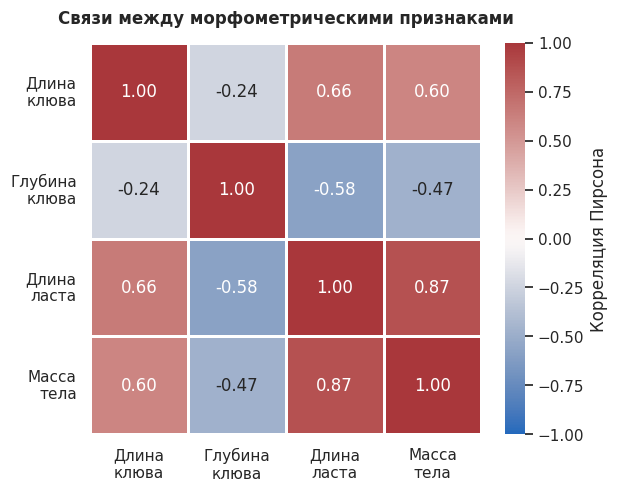

In [ ]:
correlation = morphology.rename(columns=SHORT_NAMES).corr()
fig, ax = plt.subplots(figsize=(6.1, 4.8), layout="constrained")
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
            square=True, linewidths=0.8, cbar_kws={"label": "Корреляция Пирсона"}, ax=ax)
ax.set_title("Связи между морфометрическими признаками", pad=14)
ax.tick_params(axis="both", rotation=0)
plt.show()

Длина ласта и масса тесно связаны ($r=0{,}87$) и совместно характеризуют общий размер. Длина и глубина клюва связаны слабее ($r=-0{,}24$), отражая разные стороны его строения. Сохраняем все четыре измерения ради интерпретируемости центров. При этом коррелирующие признаки размера совместно влияют на евклидово расстояние даже после масштабирования.

## 3. Предобработка данных

Исключаем две строки, в которых отсутствуют все четыре измерения. Они составляют около 0,6 % выборки. Масса измерена в граммах и по абсолютному разбросу намного превосходит размеры в миллиметрах. `StandardScaler` вычитает среднее каждого признака и делит значения на его стандартное отклонение с делителем $n$. Тогда один сдвиг на стандартное отклонение даёт одинаковый вклад в квадрат расстояния для любого измерения. Такой выбор согласуется с результатом одномерной проверки выбросов.

In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(morphology)
scaled = pd.DataFrame(X, index=morphology.index, columns=morphology.columns)
display(pd.DataFrame({
    "Среднее до": scaler.mean_,
    "Ст. откл. до": scaler.scale_,
    "Среднее после": scaled.mean().to_numpy().round(6) + 0.0,
    "Ст. откл. после": scaled.std(ddof=0).to_numpy(),
}, index=list(FEATURES.values())).round(3))

# При вызове kneighbors без X собственное наблюдение исключается из соседей.
neighbors = NearestNeighbors(n_neighbors=5).fit(X)
fifth_distance = neighbors.kneighbors()[0][:, -1]
q1_distance, q3_distance = np.quantile(fifth_distance, [0.25, 0.75])
distance_limit = q3_distance + 1.5 * (q3_distance - q1_distance)
isolated = fifth_distance > distance_limit
print(f"Порог для расстояния до пятого соседа: {distance_limit:.3f}. "
      f"Выше порога: {isolated.sum()} из {len(X)}.")
most_isolated = morphology.assign(**{"Расстояние до 5-го соседа": fifth_distance})
display(most_isolated.nlargest(5, "Расстояние до 5-го соседа").rename(columns=FEATURES).round(3))

,Среднее до,Ст. откл. до,Среднее после,Ст. откл. после
"Длина клюва, мм",43.922,5.452,0.0,1.0
"Глубина клюва, мм",17.151,1.972,0.0,1.0
"Длина ласта, мм",200.915,14.041,0.0,1.0
"Масса тела, г",4201.754,800.781,0.0,1.0


Порог для расстояния до пятого соседа: 0.892. Выше порога: 16 из 342.


,"Длина клюва, мм","Глубина клюва, мм","Длина ласта, мм","Масса тела, г",Расстояние до 5-го соседа
169,58.0,17.8,181.0,3700.0,1.686
253,59.6,17.0,230.0,6050.0,1.589
189,52.0,20.7,210.0,4800.0,1.200
14,34.6,21.1,198.0,4400.0,1.162
190,46.9,16.6,192.0,2700.0,1.031


В четырёхмерном пространстве у 16 объектов расстояние до пятого соседа превышает порог 0,892. Этот критерий отмечает низкую локальную плотность, включая крайние точки реальных групп. Все измерения у этих особей остаются в границах Тьюки. Сохраняем наблюдения и отдельно измеряем изменение разбиения при их исключении.

### 3.1. Матрица диаграмм рассеивания

На диагонали показаны распределения, ниже диагонали — пары стандартизованных признаков. Цвет для всех наблюдений общий, так как на этом этапе оценивается структура без известных видов.

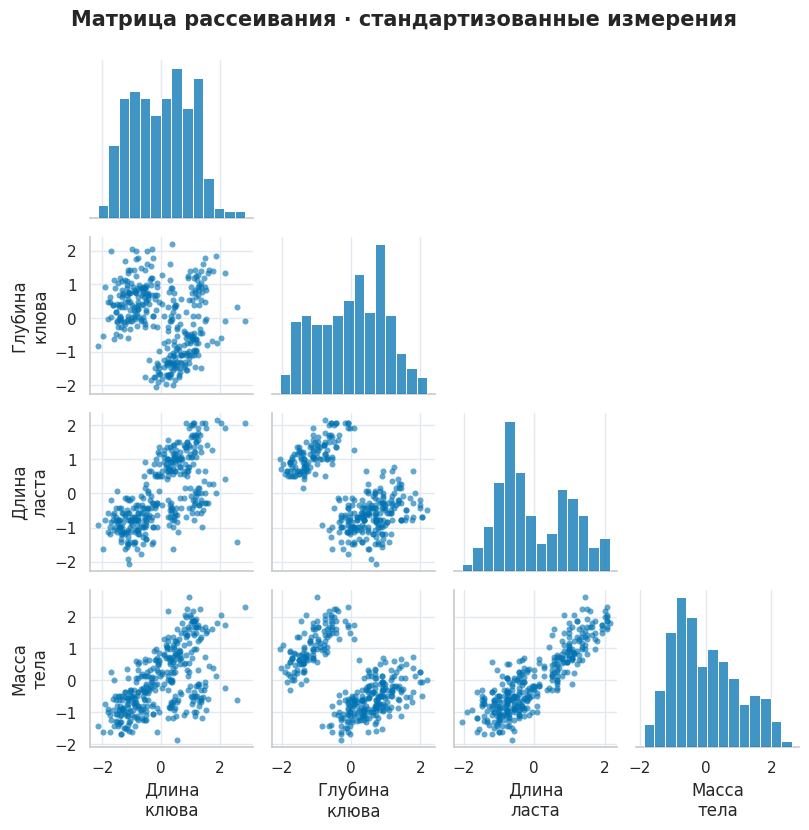

In [ ]:
pair_grid = sns.PairGrid(scaled.rename(columns=SHORT_NAMES), corner=True, height=2.12, diag_sharey=False)
pair_grid.map_lower(sns.scatterplot, color=BLUE, s=19, alpha=0.62, linewidth=0)
pair_grid.map_diag(sns.histplot, color=BLUE, bins=14, edgecolor="white")
pair_grid.figure.subplots_adjust(top=0.92, left=0.13, bottom=0.11, wspace=0.12, hspace=0.12)
pair_grid.figure.suptitle("Матрица рассеивания · стандартизованные измерения", fontsize=15, fontweight="bold")
plt.show()

На проекциях с длиной ласта и массой видны два основных скопления. У более лёгких особей длина клюва заметно варьирует, поэтому возможно более подробное разбиение на три группы. Облака вытянуты вдоль коррелирующих признаков, местами перекрываются и могут различаться по размерам и плотности.

**K-средних** даёт базовое разбиение на компактные группы вокруг центроидов и позволяет оценить уменьшение внутрикластерной суммы квадратов. Границы между его группами линейны в пространстве признаков. **Метод Уорда** начинает с отдельных объектов и на каждом шаге выбирает слияние с наименьшим приростом внутрикластерной суммы квадратов. Он показывает вложенную структуру и позволяет сравнить крупные группы с более мелкими срезами того же дерева. Оба метода склонны формировать компактные кластеры, поэтому зоны перекрытия требуют особого внимания.

## 4. Ход работы

### 4.1. Подбор числа кластеров и влияние параметра $k$

Для K-средних используем инициализацию `k-means++`, десять запусков на каждое $k$ (`n_init=10`) и фиксированный `random_state=42`. Для дендрограммы Уорда используется евклидова метрика. Инерция (SSE) — сумма квадратов расстояний от точек до центров своих групп. Для K-средних она рассчитана при $k=1,\ldots,10$. Силуэт и дополнительные метрики обоих методов рассчитаны при $k=2,\ldots,10$.

Силуэт объекта равен $(b-a)/\max(a,b)$, где $a$ — среднее расстояние до своего кластера, а $b$ — наименьшее среднее расстояние до другого кластера. Больший средний силуэт означает более чёткое разделение. Индекс Калински–Харабаша (CH) сравнивает межкластерное и внутрикластерное рассеяние с поправкой на число кластеров. Для него большее значение предпочтительно. У индекса Дэвиса–Болдина (DB) предпочтительно меньшее значение.

На графике локтя отмечаем точку с максимальным отступом от хорды, соединяющей первую и последнюю точки на нормированных осях. Основной критерий выбора $k$ — максимум силуэта. Разбиение около локтя рассматриваем как дополнительный вариант детализации.

Максимум силуэта: K-средних k=2, Уорд k=2. Локоть: k=3.


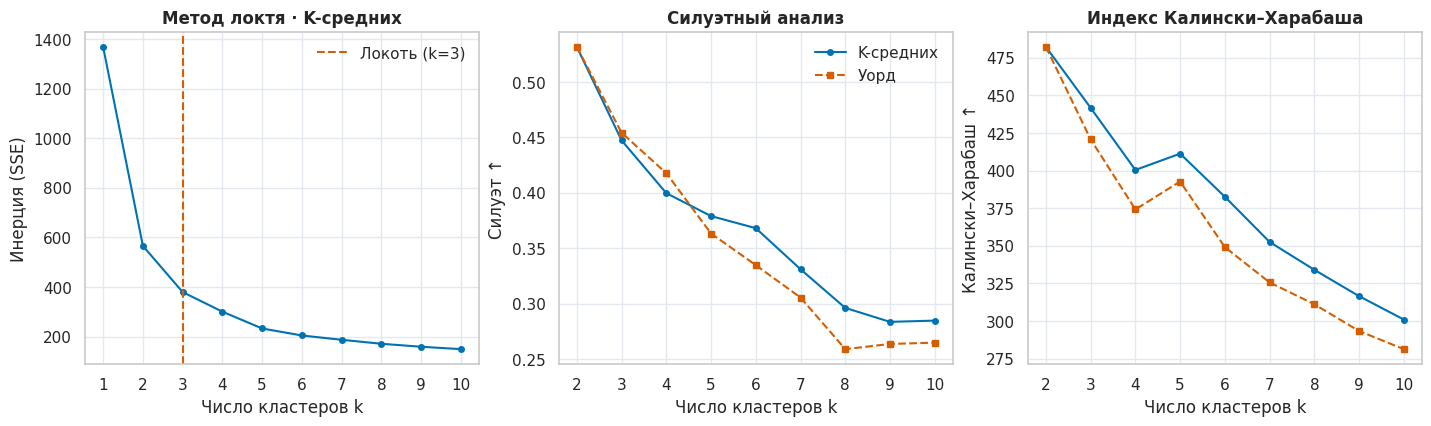

,Инерция,"Снижение SSE к предыдущему k, %",Силуэт ↑,Калински–Харабаш ↑,Дэвис–Болдин ↓
k,,,,,
2,565.708,58.647,0.532,482.191,0.714
3,379.393,32.935,0.447,441.677,0.944
4,300.400,20.821,0.400,400.410,0.944
5,232.605,22.568,0.379,411.243,0.971
6,204.393,12.129,0.368,382.570,0.995
7,187.029,8.495,0.331,352.553,1.075
8,170.980,8.581,0.296,334.045,1.151
9,158.996,7.009,0.283,316.516,1.200
10,149.363,6.059,0.285,300.973,1.201


In [ ]:
KMEANS, WARD = "K-средних", "Уорд"
METHODS = (KMEANS, WARD)
METHOD_COLORS = {KMEANS: BLUE, WARD: ORANGE}
candidate_k = np.arange(2, 11)


def fit_kmeans(values, k):
    with threadpool_limits(limits=1):
        return KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(values)


def ward_linkage(values):
    return linkage(values, method="ward", metric="euclidean")


def internal_scores(values, labels):
    return {
        "Силуэт ↑": silhouette_score(values, labels),
        "Калински–Харабаш ↑": calinski_harabasz_score(values, labels),
        "Дэвис–Болдин ↓": davies_bouldin_score(values, labels),
    }


km_models = {k: fit_kmeans(X, k) for k in range(1, 11)}
hierarchy = ward_linkage(X)
ward_cuts = dict(zip(candidate_k, cut_tree(hierarchy, n_clusters=candidate_k).T))
raw_partitions = {
    (k, method): labels
    for k in candidate_k
    for method, labels in ((KMEANS, km_models[k].labels_), (WARD, ward_cuts[k]))
}
scores_by_k = pd.DataFrame([
    {"k": k, "Метод": method, **internal_scores(X, labels)}
    for (k, method), labels in raw_partitions.items()
]).set_index(["k", "Метод"])

inertia = pd.Series({k: model.inertia_ for k, model in km_models.items()}, name="Инерция")
k_position = (inertia.index - inertia.index.min()) / (inertia.index.max() - inertia.index.min())
relative_decrease = (inertia.iloc[0] - inertia) / (inertia.iloc[0] - inertia.iloc[-1])
elbow_k = int((relative_decrease - k_position).idxmax())
best_k = {
    method: int(scores_by_k.xs(method, level="Метод")["Силуэт ↑"].idxmax())
    for method in METHODS
}
print(f"Максимум силуэта: K-средних k={best_k[KMEANS]}, Уорд k={best_k[WARD]}. Локоть: k={elbow_k}.")

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.15), layout="constrained")
axes[0].plot(inertia.index, inertia, color=BLUE, marker="o", markersize=4)
axes[0].axvline(elbow_k, label=f"Локоть (k={elbow_k})", color=ORANGE, linestyle="--")
axes[0].set(title="Метод локтя · K-средних", xlabel="Число кластеров k", ylabel="Инерция (SSE)")
axes[0].legend(frameon=False)
for ax, score, title in zip(axes[1:], ["Силуэт ↑", "Калински–Харабаш ↑"], ["Силуэтный анализ", "Индекс Калински–Харабаша"]):
    for method, style in zip(METHODS, ["o-", "s--"]):
        values = scores_by_k.xs(method, level="Метод")[score]
        ax.plot(values.index, values, style, label=method, color=METHOD_COLORS[method], markersize=4)
    ax.set(title=title, xlabel="Число кластеров k", ylabel=score)
axes[1].legend(frameon=False)
axes[0].set_xticks(inertia.index)
for ax in axes[1:]:
    ax.set_xticks(candidate_k)
plt.show()

kmeans_sensitivity = scores_by_k.xs(KMEANS, level="Метод").copy()
kmeans_sensitivity.insert(0, "Инерция", inertia)
kmeans_sensitivity.insert(1, "Снижение SSE к предыдущему k, %", -100 * inertia.pct_change())
display(kmeans_sensitivity.round(3))

При переходе от $k=2$ к $k=3$ инерция K-средних снижается с 565,71 до 379,39, примерно на 33 %. Средний силуэт при этом падает с 0,53 до 0,45. При $k=4$ он снижается до 0,40 и далее остаётся ниже. Инерция продолжает уменьшаться при дроблении групп, поэтому её минимум на сетке непригоден как самостоятельный критерий. Силуэт, CH и DB у обоих методов отдают предпочтение $k=2$. Локоть при $k=3$ указывает на более мелкую структуру, которую стоит проверить по центрам и устойчивости.

### 4.2. Дендрограмма метода Уорда

k=2 · высоты соседних слияний 18.59 и 40.06. Промежуток 21.46.
k=3 · высоты соседних слияний 12.35 и 18.59. Промежуток 6.24.


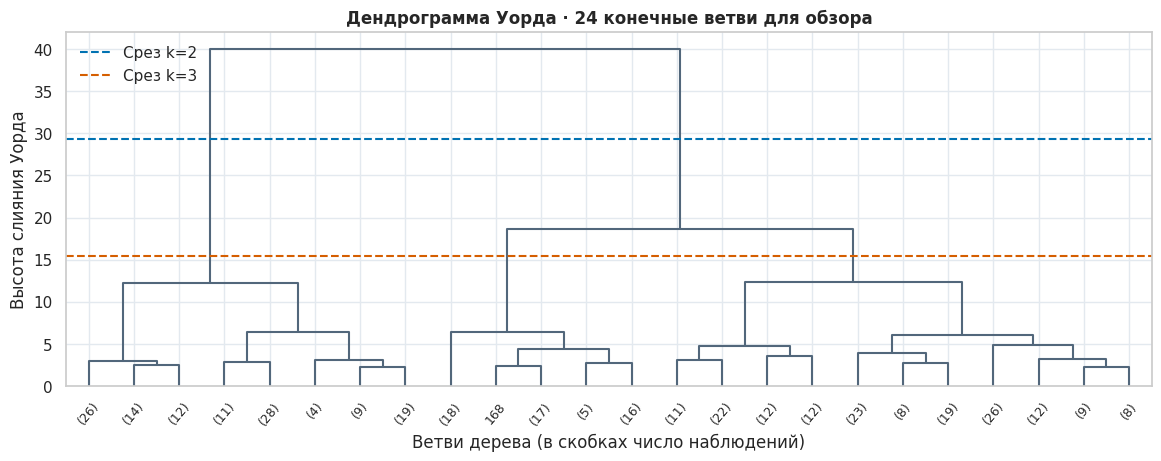

In [ ]:
report_k = sorted({*best_k.values(), elbow_k})
fig, ax = plt.subplots(figsize=(11.5, 4.5), layout="constrained")
dendrogram(hierarchy, truncate_mode="lastp", p=24, leaf_rotation=50, leaf_font_size=9,
           show_leaf_counts=True, color_threshold=0, above_threshold_color="#52677B", ax=ax)
for k, color in zip(report_k, [BLUE, ORANGE, GREEN]):
    lower_height, upper_height = hierarchy[-k, 2], hierarchy[-k + 1, 2]
    ax.axhline((lower_height + upper_height) / 2, color=color, linestyle="--", label=f"Срез k={k}")
    print(f"k={k} · высоты соседних слияний {lower_height:.2f} и {upper_height:.2f}. "
          f"Промежуток {upper_height - lower_height:.2f}.")
ax.set(title="Дендрограмма Уорда · 24 конечные ветви для обзора",
       xlabel="Ветви дерева (в скобках число наблюдений)", ylabel="Высота слияния Уорда")
ax.legend(frameon=False, loc="upper left")
plt.show()

Скачок высоты от 18,59 до 40,06 оставляет широкий диапазон высот среза, при которых получаются два кластера. Для трёх кластеров промежуток составляет 6,24. Метрики и центры ниже сравниваются для обоих $k$.

### 4.3. Внутренние показатели, центры и расстояния

Номера кластеров присваиваем по возрастанию средней длины ласта отдельно в каждом разбиении. Центр любой группы — среднее четырёх измерений. В исходных единицах это описание типичной особи, а в стандартизованном пространстве центры дают сопоставимые межкластерные расстояния. Компактность оценивается средним попарным расстоянием внутри группы и среднеквадратическим расстоянием (RMS) до её центра.

In [ ]:
def number_by_flipper(labels):
    order = morphology.groupby(labels)["flipper_length_mm"].mean().sort_values().index
    numbers = {label: count for count, label in enumerate(order, start=1)}
    return np.array([numbers[label] for label in labels])


partitions = {
    (k, method): number_by_flipper(raw_partitions[k, method])
    for k in report_k for method in METHODS
}
centers = {}
comparison = []
compactness = []
centroid_distances = []
for (k, method), labels in partitions.items():
    group = pd.Series(labels, index=morphology.index, name="Кластер")
    original_centers = morphology.groupby(group).mean()
    centers[k, method] = original_centers
    center_z = scaler.transform(original_centers)
    pair_distances = pdist(center_z)
    distance_labels = [f"{a}–{b}" for a, b in combinations(original_centers.index, 2)]
    centroid_distances.append({"k": k, "Метод": method, **dict(zip(distance_labels, pair_distances))})

    sse = ((X - center_z[labels - 1]) ** 2).sum()
    comparison.append({
        "k": k, "Метод": method, **scores_by_k.loc[(k, method)].to_dict(),
        "SSE ↓": sse, "Мин. расстояние между центрами": pair_distances.min(),
    })
    object_silhouettes = silhouette_samples(X, labels)
    for number in original_centers.index:
        mask = labels == number
        group_values = X[mask]
        group_residuals = group_values - center_z[number - 1]
        compactness.append({
            "k": k, "Метод": method, "Кластер": number, "Число особей": mask.sum(),
            "Ср. попарное расстояние": pdist(group_values).mean(),
            "RMS до центра": np.sqrt((group_residuals ** 2).sum(axis=1).mean()),
            "Средний силуэт": object_silhouettes[mask].mean(),
        })

comparison_table = pd.DataFrame(comparison).set_index(["k", "Метод"])
center_table = pd.concat(centers, names=["k", "Метод", "Кластер"]).rename(columns=FEATURES)
compactness_table = pd.DataFrame(compactness).set_index(["k", "Метод", "Кластер"])
distance_table = pd.DataFrame(centroid_distances).set_index(["k", "Метод"])
display(Markdown("**Сравнение внутренних метрик в четырёхмерном пространстве**"))
display(comparison_table.round(3))
display(Markdown("**Центры кластеров в исходных единицах**"))
display(center_table.round(2))
display(Markdown("**Размеры и компактность кластеров**"))
display(compactness_table.round(3))
display(Markdown("**Расстояния между парами центров в стандартизованном пространстве**"))
display(distance_table.round(3).fillna("—"))

**Сравнение внутренних метрик в четырёхмерном пространстве**

Силуэт ↑  Калински–Харабаш ↑  Дэвис–Болдин ↓    SSE ↓  \
k Метод                                                              
2 K-средних     0.532             482.191           0.714  565.708   
  Уорд          0.532             482.191           0.714  565.708   
3 K-средних     0.447             441.677           0.944  379.393   
  Уорд          0.454             420.718           0.846  392.865   

             Мин. расстояние между центрами  
k Метод                                      
2 K-средних                           3.192  
  Уорд                                3.192  
3 K-средних                           1.885  
  Уорд                                2.025

**Центры кластеров в исходных единицах**

Длина клюва, мм  Глубина клюва, мм  Длина ласта, мм  \
k Метод     Кластер                                                        
2 K-средних 1                  41.91              18.37           191.78   
            2                  47.50              14.98           217.19   
  Уорд      1                  41.91              18.37           191.78   
            2                  47.50              14.98           217.19   
3 K-средних 1                  38.21              18.11           188.40   
            2                  47.53              18.76           196.90   
            3                  47.50              14.98           217.19   
  Уорд      1                  39.15              18.29           189.90   
            2                  49.75              18.60           197.11   
            3                  47.50              14.98           217.19   

                     Масса тела, г  
k Метод     Кластер                 
2 K-средних 1              3710.73  
            2              5076.02  
  Уорд      1              3710.73  
            2              5076.02  
3 K-средних 1              3584.66  
            2              3902.01  
            3              5076.02  
  Уорд      1              3675.77  
            2              3810.09  
            3              5076.02

**Размеры и компактность кластеров**

Число особей  Ср. попарное расстояние  RMS до центра  \
k Метод     Кластер                                                         
2 K-средних 1                 219                    1.796          1.388   
            2                 123                    1.370          1.080   
  Уорд      1                 219                    1.796          1.388   
            2                 123                    1.370          1.080   
3 K-средних 1                 132                    1.270          0.963   
            2                  87                    1.506          1.141   
            3                 123                    1.370          1.080   
  Уорд      1                 162                    1.445          1.102   
            2                  57                    1.247          0.960   
            3                 123                    1.370          1.080   

                     Средний силуэт  
k Метод     Кластер                  
2 K-средних 1                 0.485  
            2                 0.614  
  Уорд      1                 0.485  
            2                 0.614  
3 K-средних 1                 0.431  
            2                 0.301  
            3                 0.568  
  Уорд      1                 0.370  
            2                 0.458  
            3                 0.564

**Расстояния между парами центров в стандартизованном пространстве**

1–2    1–3    2–3
k Метод                         
2 K-средних  3.192      —      —
  Уорд       3.192      —      —
3 K-средних  1.885  3.619  2.813
  Уорд       2.025  3.463  2.843

При $k=2$ оба алгоритма получили одинаковые группы из 219 и 123 особей. Евклидово расстояние между центрами в стандартизованном пространстве равно 3,19. В большой группе среднее попарное расстояние равно 1,80 и RMS до центра равно 1,39. В малой — 1,37 и 1,08 соответственно. Меньшая группа компактнее и имеет более высокий средний силуэт (0,61 против 0,49).

При $k=3$ группа из 123 особей сохраняется, а большая группа разделяется на две. Ближайшие центры отстоят на 1,88 у K-средних и 2,02 у Уорда. Именно для этих соседних групп характерны меньшие силуэты, особенно для промежуточного кластера K-средних (0,30). У K-средних ниже SSE и выше CH, у Уорда выше силуэт и ниже DB. Выбор метрики влияет на оценку мелкого разбиения.

### 4.4. Внешняя проверка по видам

Индекс Rand измеряет долю согласованных пар, которые в обоих разбиениях принадлежат одной группе или в обоих разделены. Скорректированный индекс Rand (ARI) учитывает случайное согласие. Попарный индекс Жаккара берёт отношение числа пар, объединённых в обоих разбиениях, к числу пар, объединённых хотя бы в одном. NMI измеряет общую информацию между метками и нормирует её в диапазон от 0 до 1. Все показатели инвариантны к нумерации кластеров.

In [ ]:
species = penguins.loc[morphology.index, "species"].to_numpy()


def count_pairs(counts):
    return (counts * (counts - 1) // 2).sum()


external = []
species_tables = {}
for (k, method), labels in partitions.items():
    table = pd.crosstab(labels, species, rownames=["Кластер"], colnames=["Вид"])
    species_tables[k, method] = table
    counts = table.to_numpy()
    common_pairs = count_pairs(counts)
    union_pairs = count_pairs(counts.sum(axis=0)) + count_pairs(counts.sum(axis=1)) - common_pairs
    external.append({
        "k": k, "Метод": method, "Rand ↑": rand_score(species, labels),
        "ARI ↑": adjusted_rand_score(species, labels), "Жаккар ↑": common_pairs / union_pairs,
        "NMI ↑": normalized_mutual_info_score(species, labels),
    })

external_table = pd.DataFrame(external).set_index(["k", "Метод"])
display(external_table.round(3))
display(pd.concat(species_tables, names=["k", "Метод", "Кластер"]))
method_agreement = pd.Series({
    k: adjusted_rand_score(partitions[k, KMEANS], partitions[k, WARD]) for k in report_k
}, name="ARI между методами")
display(method_agreement.rename_axis("k").round(3).to_frame())

Rand ↑  ARI ↑  Жаккар ↑  NMI ↑
k Метод                                    
2 K-средних   0.824  0.655     0.673  0.767
  Уорд        0.824  0.655     0.673  0.767
3 K-средних   0.906  0.793     0.763  0.786
  Уорд        0.961  0.916     0.900  0.901

Вид                  Adelie  Chinstrap  Gentoo
k Метод     Кластер                           
2 K-средних 1           151         68       0
            2             0          0     123
  Уорд      1           151         68       0
            2             0          0     123
3 K-средних 1           127          5       0
            2            24         63       0
            3             0          0     123
  Уорд      1           151         11       0
            2             0         57       0
            3             0          0     123

,ARI между методами
k,
2,1.000
3,0.789


При $k=2$ кластер 2 состоит из 123 Gentoo. Кластер 1 объединяет 151 Adelie и 68 Chinstrap, что объясняет ARI 0,655 при высоком силуэте. При $k=3$ Уорд лучше воспроизводит видовую структуру (ARI 0,916 против 0,793). У Уорда все 151 Adelie находятся в одном кластере вместе с 11 Chinstrap, а ещё 57 Chinstrap образуют отдельную группу. K-средних отделяет 63 Chinstrap вместе с 24 Adelie, а ещё 5 Chinstrap относит в группу с 127 Adelie. ARI между двумя методами при $k=3$ равен 0,789. Индексы Жаккара и NMI также дают Уорду более высокую оценку за соответствие видам при $k=3$.

### 4.5. Устойчивость на подвыборках и роль признаков

Строим 40 подвыборок по 80 % наблюдений без возвращения. В каждом повторе заново стандартизуем измерения и обучаем оба метода при том же $k$. ARI сравнивает новое разбиение с исходным на тех же особях. Дополнительно повторяем расчёт после исключения 16 изолированных объектов и после исключения каждого измерения по отдельности. Для последней проверки низкий ARI означает, что удалённое измерение заметно изменило структуру групп.

In [ ]:
def refit_partitions(values):
    values_z = StandardScaler().fit_transform(values)
    cuts = cut_tree(ward_linkage(values_z), n_clusters=report_k)
    predictions = {}
    for k, ward_labels in zip(report_k, cuts.T):
        predictions[k, KMEANS] = fit_kmeans(values_z, k).labels_
        predictions[k, WARD] = ward_labels
    return predictions


rng = np.random.default_rng(SEED)
stability_runs = {key: [] for key in partitions}
for _ in range(40):
    sample = np.sort(rng.choice(len(morphology), size=round(0.8 * len(morphology)), replace=False))
    sample_partitions = refit_partitions(morphology.iloc[sample])
    for key, labels in sample_partitions.items():
        stability_runs[key].append(adjusted_rand_score(partitions[key][sample], labels))

central_partitions = refit_partitions(morphology.iloc[~isolated])
stability_table = pd.DataFrame([
    {
        "k": k, "Метод": method, "Медиана ARI": np.median(runs),
        "5-й процентиль": np.quantile(runs, 0.05), "95-й процентиль": np.quantile(runs, 0.95),
        "ARI без изолированных объектов": adjusted_rand_score(
            partitions[k, method][~isolated], central_partitions[k, method]
        ),
    }
    for (k, method), runs in stability_runs.items()
]).set_index(["k", "Метод"])
display(stability_table.round(3))

ablation = []
for name, description in FEATURES.items():
    reduced_partitions = refit_partitions(morphology.drop(columns=name))
    ablation.append(pd.Series({
        key: adjusted_rand_score(partitions[key], labels) for key, labels in reduced_partitions.items()
    }, name=description))
ablation_table = pd.DataFrame(ablation).rename_axis(index="Исключённый признак", columns=["k", "Метод"])
display(ablation_table.round(3))

Медиана ARI  5-й процентиль  95-й процентиль  \
k Метод                                                     
2 K-средних        1.000           1.000             1.00   
  Уорд             1.000           1.000             1.00   
3 K-средних        1.000           0.871             1.00   
  Уорд             0.951           0.673             0.98   

             ARI без изолированных объектов  
k Метод                                      
2 K-средних                           1.000  
  Уорд                                1.000  
3 K-средних                           1.000  
  Уорд                                0.959

k                           2                3       
Метод               K-средних   Уорд K-средних   Уорд
Исключённый признак                                  
Длина клюва, мм         1.000  1.000     0.609  0.563
Глубина клюва, мм       0.738  0.919     0.844  0.886
Длина ласта, мм         0.988  0.988     0.857  0.943
Масса тела, г           0.988  1.000     0.857  0.946

При $k=2$ разбиение воспроизвелось на всех 40 подвыборках у обоих методов. Исключение изолированных особей также даёт ARI 1,00 на оставшихся точках. При $k=3$ медиана ARI на подвыборках составляет 1,00 у K-средних и 0,95 у Уорда. Нижние 5-е процентили (0,87 и 0,67) показывают, что мелкое разбиение чувствительнее к составу данных, особенно у Уорда.

В проверке признаков при $k=2$ наиболее заметно влияет глубина клюва. При $k=3$ сильнее всего меняет разбиение исключение длины клюва (ARI 0,609 для K-средних и 0,563 для Уорда). Этот результат согласуется с различиями центров соседних кластеров. Исключение массы или длины ласта по отдельности слабо влияет на основное разбиение, что согласуется с их сильной корреляцией.

## 5. Визуализация результатов

PCA обучается на четырёх стандартизованных измерениях и используется для проекции объектов и центров. Алгоритмы и все метрики рассчитаны в исходном четырёхмерном стандартизованном пространстве. Обе строки рисунка используют одинаковые оси. Номера кластеров относятся к соответствующему $k$, а кресты обозначают центры.

Две компоненты объясняют 88.16% суммарной дисперсии.


,PC1,PC2
"Длина клюва, мм",0.455,0.597
"Глубина клюва, мм",-0.400,0.798
"Длина ласта, мм",0.576,0.002
"Масса тела, г",0.548,0.084


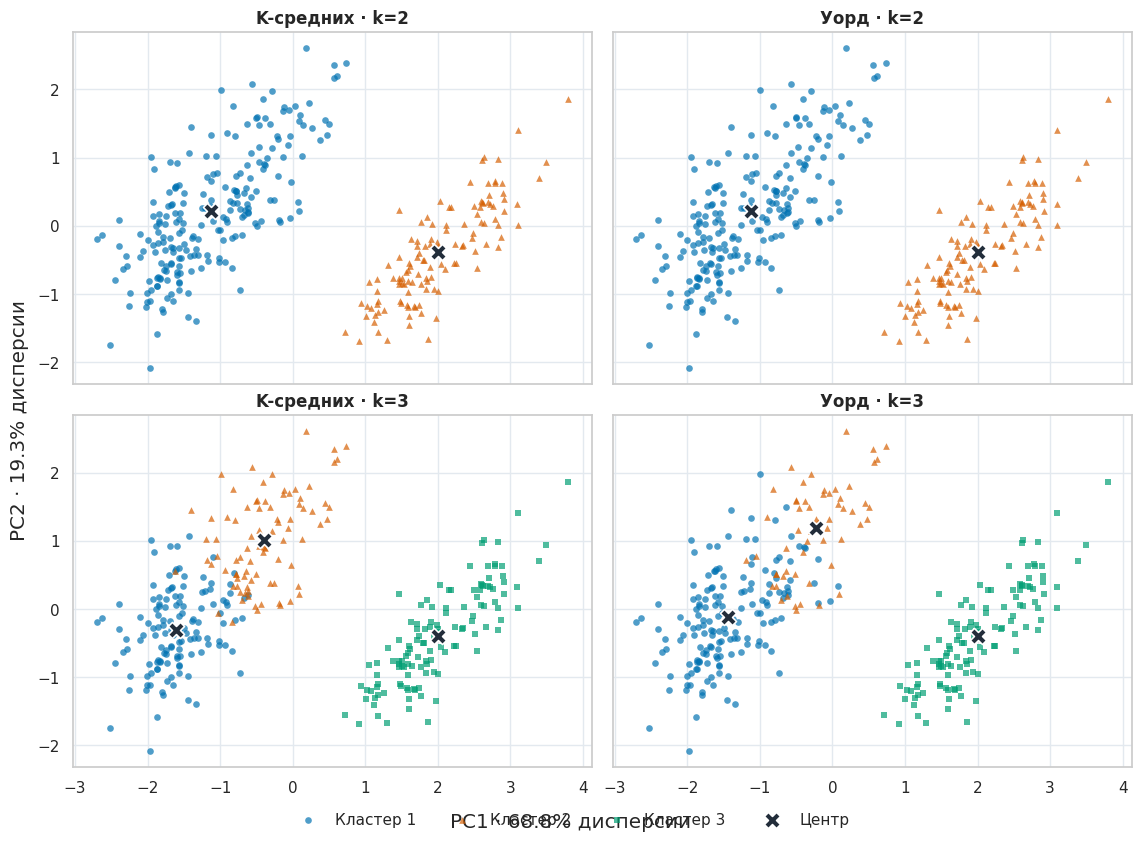

In [ ]:
pca = PCA(n_components=2, svd_solver="full")
projection = pca.fit_transform(X)
explained = 100 * pca.explained_variance_ratio_
print(f"Две компоненты объясняют {explained.sum():.2f}% суммарной дисперсии.")
display(pd.DataFrame(pca.components_.T, index=list(FEATURES.values()), columns=["PC1", "PC2"]).round(3))

fig, axes = plt.subplots(len(report_k), len(METHODS), figsize=(11.3, 8.3),
                         sharex=True, sharey=True, layout="constrained", squeeze=False)
for row, k in enumerate(report_k):
    for col, method in enumerate(METHODS):
        ax = axes[row, col]
        labels = partitions[k, method]
        for number, color, marker in zip(range(1, k + 1), [BLUE, ORANGE, GREEN], ["o", "^", "s"]):
            points = projection[labels == number]
            ax.scatter(points[:, 0], points[:, 1], color=color, marker=marker, alpha=0.69,
                       s=23, linewidths=0, label=f"Кластер {number}")
        projected_centers = pca.transform(scaler.transform(centers[k, method]))
        ax.scatter(projected_centers[:, 0], projected_centers[:, 1], color="#222D3A", marker="X",
                   edgecolor="white", linewidths=1.15, s=135, zorder=3, label="Центр")
        ax.set_title(f"{method} · k={k}")
handles, labels = axes[-1, -1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=len(labels), frameon=False)
fig.supxlabel(f"PC1 · {explained[0]:.1f}% дисперсии")
fig.supylabel(f"PC2 · {explained[1]:.1f}% дисперсии")
plt.show()

Первые две компоненты сохраняют 88,16 % дисперсии. В PC1 велики коэффициенты длины ласта и массы тела. PC2 преимущественно отражает длину и глубину клюва. На PCA-проекции хорошо видны два основных облака и более слабая граница внутри группы меньших особей.

При $k=2$ центр группы из 123 особей имеет массу 5076 г, ласт длиной 217 мм и клюв глубиной около 15,0 мм. У группы из 219 особей центр соответствует 3711 г, 192 мм и 18,4 мм. Таким образом, основной результат разделяет более крупных особей с менее глубоким клювом и более лёгких особей с глубоким клювом.

При $k=3$ устойчиво сохраняется группа крупных особей. Различия между двумя меньшими группами особенно заметны по длине клюва. У Уорда их центры составляют 39,15 мм и 49,75 мм по этому признаку, а у K-средних — 38,21 мм и 47,53 мм. Уорд выделяет более узкую группу с длинным клювом, тогда как K-средних включает в неё больше наблюдений из зоны перекрытия.

## 6. Заключение

Для общего морфометрического разбиения обосновано **$k=2$**. Оба метода дали одинаковый результат, средний силуэт около 0,53 и индекс Калински–Харабаша 482,19. Разбиение сохранилось на всех проверенных подвыборках. Метод Уорда дополнительно показывает вложенную структуру на дендрограмме, а K-средних даёт компактное описание через центроиды.

Если задача состоит в выделении более мелких морфологических групп, локоть поддерживает **$k=3$**. В этом варианте Уорд ближе к известным видам (ARI 0,916), а K-средних устойчивее к изменению состава подвыборки. Главная неопределённость связана с границей между Adelie и Chinstrap. Это отражает различие задач разделения по морфометрии и восстановления видовых меток.

## 7. Список источников

1. P. Pandey. *Palmer Archipelago (Antarctica) penguin data*. Версия 1. [Kaggle](https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data)
2. Документация scikit-learn. [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) · [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) · [Оценка кластеризации](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation) · [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
3. Документация SciPy. [Связи в иерархической кластеризации](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html) · [Дендрограмма](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html)

## 8. Приложение. Полный листинг программного кода

Код приведён в порядке выполнения ячеек Jupyter.

<details>
<summary>Развернуть полный листинг</summary>

```python
# Ячейка 1
%matplotlib inline

from hashlib import sha256
from importlib.metadata import version
from itertools import combinations
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from scipy.spatial.distance import pdist
from scipy.stats import norm, shapiro
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    rand_score,
    silhouette_samples,
    silhouette_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
DATASET_ID = "parulpandey/palmer-archipelago-antarctica-penguin-data"
FEATURES = {
    "culmen_length_mm": "Длина клюва, мм",
    "culmen_depth_mm": "Глубина клюва, мм",
    "flipper_length_mm": "Длина ласта, мм",
    "body_mass_g": "Масса тела, г",
}
SHORT_NAMES = dict(zip(FEATURES, ["Длина\nклюва", "Глубина\nклюва", "Длина\nласта", "Масса\nтела"]))
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.0,
              rc={"grid.color": "#e3e9ef", "axes.titleweight": "bold"})

csv_path = Path("penguins_size.csv")
if not csv_path.is_file():
    dataset_dir = Path(kagglehub.dataset_download(DATASET_ID))
    csv_path = dataset_dir / csv_path.name
    print(f"KaggleHub · каталог версии {dataset_dir.name}")

penguins = pd.read_csv(csv_path)
print(f"{csv_path.name} · {penguins.shape[0]} строк × {penguins.shape[1]} столбцов")
print(f"SHA-256 файла: {sha256(csv_path.read_bytes()).hexdigest()}")
print(" · ".join(f"{pkg} {version(pkg)}" for pkg in ("pandas", "scipy", "scikit-learn", "kagglehub")))

schema = pd.DataFrame({
    "Тип pandas": penguins.dtypes.astype(str),
    "Пропущено (NaN)": penguins.isna().sum(),
    "Уникальных значений": penguins.nunique(),
})
display(schema)
print("Категории пола в исходном файле")
display(penguins["sex"].value_counts(dropna=False).rename("Число записей").to_frame())

# Ячейка 2
morphology = penguins.loc[:, list(FEATURES)].dropna()
print(f"Полных морфометрических наблюдений: {len(morphology)}. "
      f"Исключено строк с пропусками: {len(penguins) - len(morphology)}.")
display(morphology.rename(columns=FEATURES).describe().T.round(2))

q1, q3 = morphology.quantile(0.25), morphology.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outside_fences = (morphology.lt(lower) | morphology.gt(upper)).sum()
normality = pd.DataFrame(index=morphology.columns)
normality["Асимметрия"] = morphology.skew().round(3)
normality["Нижняя граница Тьюки"] = lower.round(2)
normality["Верхняя граница Тьюки"] = upper.round(2)
normality["За границами"] = outside_fences
normality["p (Шапиро–Уилк)"] = [f"{shapiro(morphology[name]).pvalue:.2e}" for name in FEATURES]
display(normality.rename(index=FEATURES))

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), layout="constrained")
for ax, (name, label) in zip(axes.flat, FEATURES.items()):
    values = morphology[name]
    grid = np.linspace(values.min(), values.max(), 250)
    ax.hist(values, bins=15, density=True, color=BLUE, alpha=0.74, edgecolor="white")
    ax.plot(grid, norm.pdf(grid, loc=values.mean(), scale=values.std()),
            color="#252F43", linestyle="--", label="Нормальная плотность")
    ax.set(xlabel=label, ylabel="Плотность")
axes[0, 0].legend(frameon=False, loc="upper left", fontsize=9)
fig.suptitle("Распределения морфометрических признаков", fontsize=15, fontweight="bold")
plt.show()

# Ячейка 3
correlation = morphology.rename(columns=SHORT_NAMES).corr()
fig, ax = plt.subplots(figsize=(6.1, 4.8), layout="constrained")
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
            square=True, linewidths=0.8, cbar_kws={"label": "Корреляция Пирсона"}, ax=ax)
ax.set_title("Связи между морфометрическими признаками", pad=14)
ax.tick_params(axis="both", rotation=0)
plt.show()

# Ячейка 4
scaler = StandardScaler()
X = scaler.fit_transform(morphology)
scaled = pd.DataFrame(X, index=morphology.index, columns=morphology.columns)
display(pd.DataFrame({
    "Среднее до": scaler.mean_,
    "Ст. откл. до": scaler.scale_,
    "Среднее после": scaled.mean().to_numpy().round(6) + 0.0,
    "Ст. откл. после": scaled.std(ddof=0).to_numpy(),
}, index=list(FEATURES.values())).round(3))

# При вызове kneighbors без X собственное наблюдение исключается из соседей.
neighbors = NearestNeighbors(n_neighbors=5).fit(X)
fifth_distance = neighbors.kneighbors()[0][:, -1]
q1_distance, q3_distance = np.quantile(fifth_distance, [0.25, 0.75])
distance_limit = q3_distance + 1.5 * (q3_distance - q1_distance)
isolated = fifth_distance > distance_limit
print(f"Порог для расстояния до пятого соседа: {distance_limit:.3f}. "
      f"Выше порога: {isolated.sum()} из {len(X)}.")
most_isolated = morphology.assign(**{"Расстояние до 5-го соседа": fifth_distance})
display(most_isolated.nlargest(5, "Расстояние до 5-го соседа").rename(columns=FEATURES).round(3))

# Ячейка 5
pair_grid = sns.PairGrid(scaled.rename(columns=SHORT_NAMES), corner=True, height=2.12, diag_sharey=False)
pair_grid.map_lower(sns.scatterplot, color=BLUE, s=19, alpha=0.62, linewidth=0)
pair_grid.map_diag(sns.histplot, color=BLUE, bins=14, edgecolor="white")
pair_grid.figure.subplots_adjust(top=0.92, left=0.13, bottom=0.11, wspace=0.12, hspace=0.12)
pair_grid.figure.suptitle("Матрица рассеивания · стандартизованные измерения", fontsize=15, fontweight="bold")
plt.show()

# Ячейка 6
KMEANS, WARD = "K-средних", "Уорд"
METHODS = (KMEANS, WARD)
METHOD_COLORS = {KMEANS: BLUE, WARD: ORANGE}
candidate_k = np.arange(2, 11)


def fit_kmeans(values, k):
    with threadpool_limits(limits=1):
        return KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(values)


def ward_linkage(values):
    return linkage(values, method="ward", metric="euclidean")


def internal_scores(values, labels):
    return {
        "Силуэт ↑": silhouette_score(values, labels),
        "Калински–Харабаш ↑": calinski_harabasz_score(values, labels),
        "Дэвис–Болдин ↓": davies_bouldin_score(values, labels),
    }


km_models = {k: fit_kmeans(X, k) for k in range(1, 11)}
hierarchy = ward_linkage(X)
ward_cuts = dict(zip(candidate_k, cut_tree(hierarchy, n_clusters=candidate_k).T))
raw_partitions = {
    (k, method): labels
    for k in candidate_k
    for method, labels in ((KMEANS, km_models[k].labels_), (WARD, ward_cuts[k]))
}
scores_by_k = pd.DataFrame([
    {"k": k, "Метод": method, **internal_scores(X, labels)}
    for (k, method), labels in raw_partitions.items()
]).set_index(["k", "Метод"])

inertia = pd.Series({k: model.inertia_ for k, model in km_models.items()}, name="Инерция")
k_position = (inertia.index - inertia.index.min()) / (inertia.index.max() - inertia.index.min())
relative_decrease = (inertia.iloc[0] - inertia) / (inertia.iloc[0] - inertia.iloc[-1])
elbow_k = int((relative_decrease - k_position).idxmax())
best_k = {
    method: int(scores_by_k.xs(method, level="Метод")["Силуэт ↑"].idxmax())
    for method in METHODS
}
print(f"Максимум силуэта: K-средних k={best_k[KMEANS]}, Уорд k={best_k[WARD]}. Локоть: k={elbow_k}.")

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.15), layout="constrained")
axes[0].plot(inertia.index, inertia, color=BLUE, marker="o", markersize=4)
axes[0].axvline(elbow_k, label=f"Локоть (k={elbow_k})", color=ORANGE, linestyle="--")
axes[0].set(title="Метод локтя · K-средних", xlabel="Число кластеров k", ylabel="Инерция (SSE)")
axes[0].legend(frameon=False)
for ax, score, title in zip(axes[1:], ["Силуэт ↑", "Калински–Харабаш ↑"], ["Силуэтный анализ", "Индекс Калински–Харабаша"]):
    for method, style in zip(METHODS, ["o-", "s--"]):
        values = scores_by_k.xs(method, level="Метод")[score]
        ax.plot(values.index, values, style, label=method, color=METHOD_COLORS[method], markersize=4)
    ax.set(title=title, xlabel="Число кластеров k", ylabel=score)
axes[1].legend(frameon=False)
axes[0].set_xticks(inertia.index)
for ax in axes[1:]:
    ax.set_xticks(candidate_k)
plt.show()

kmeans_sensitivity = scores_by_k.xs(KMEANS, level="Метод").copy()
kmeans_sensitivity.insert(0, "Инерция", inertia)
kmeans_sensitivity.insert(1, "Снижение SSE к предыдущему k, %", -100 * inertia.pct_change())
display(kmeans_sensitivity.round(3))

# Ячейка 7
report_k = sorted({*best_k.values(), elbow_k})
fig, ax = plt.subplots(figsize=(11.5, 4.5), layout="constrained")
dendrogram(hierarchy, truncate_mode="lastp", p=24, leaf_rotation=50, leaf_font_size=9,
           show_leaf_counts=True, color_threshold=0, above_threshold_color="#52677B", ax=ax)
for k, color in zip(report_k, [BLUE, ORANGE, GREEN]):
    lower_height, upper_height = hierarchy[-k, 2], hierarchy[-k + 1, 2]
    ax.axhline((lower_height + upper_height) / 2, color=color, linestyle="--", label=f"Срез k={k}")
    print(f"k={k} · высоты соседних слияний {lower_height:.2f} и {upper_height:.2f}. "
          f"Промежуток {upper_height - lower_height:.2f}.")
ax.set(title="Дендрограмма Уорда · 24 конечные ветви для обзора",
       xlabel="Ветви дерева (в скобках число наблюдений)", ylabel="Высота слияния Уорда")
ax.legend(frameon=False, loc="upper left")
plt.show()

# Ячейка 8
def number_by_flipper(labels):
    order = morphology.groupby(labels)["flipper_length_mm"].mean().sort_values().index
    numbers = {label: count for count, label in enumerate(order, start=1)}
    return np.array([numbers[label] for label in labels])


partitions = {
    (k, method): number_by_flipper(raw_partitions[k, method])
    for k in report_k for method in METHODS
}
centers = {}
comparison = []
compactness = []
centroid_distances = []
for (k, method), labels in partitions.items():
    group = pd.Series(labels, index=morphology.index, name="Кластер")
    original_centers = morphology.groupby(group).mean()
    centers[k, method] = original_centers
    center_z = scaler.transform(original_centers)
    pair_distances = pdist(center_z)
    distance_labels = [f"{a}–{b}" for a, b in combinations(original_centers.index, 2)]
    centroid_distances.append({"k": k, "Метод": method, **dict(zip(distance_labels, pair_distances))})

    sse = ((X - center_z[labels - 1]) ** 2).sum()
    comparison.append({
        "k": k, "Метод": method, **scores_by_k.loc[(k, method)].to_dict(),
        "SSE ↓": sse, "Мин. расстояние между центрами": pair_distances.min(),
    })
    object_silhouettes = silhouette_samples(X, labels)
    for number in original_centers.index:
        mask = labels == number
        group_values = X[mask]
        group_residuals = group_values - center_z[number - 1]
        compactness.append({
            "k": k, "Метод": method, "Кластер": number, "Число особей": mask.sum(),
            "Ср. попарное расстояние": pdist(group_values).mean(),
            "RMS до центра": np.sqrt((group_residuals ** 2).sum(axis=1).mean()),
            "Средний силуэт": object_silhouettes[mask].mean(),
        })

comparison_table = pd.DataFrame(comparison).set_index(["k", "Метод"])
center_table = pd.concat(centers, names=["k", "Метод", "Кластер"]).rename(columns=FEATURES)
compactness_table = pd.DataFrame(compactness).set_index(["k", "Метод", "Кластер"])
distance_table = pd.DataFrame(centroid_distances).set_index(["k", "Метод"])
display(Markdown("**Сравнение внутренних метрик в четырёхмерном пространстве**"))
display(comparison_table.round(3))
display(Markdown("**Центры кластеров в исходных единицах**"))
display(center_table.round(2))
display(Markdown("**Размеры и компактность кластеров**"))
display(compactness_table.round(3))
display(Markdown("**Расстояния между парами центров в стандартизованном пространстве**"))
display(distance_table.round(3).fillna("—"))

# Ячейка 9
species = penguins.loc[morphology.index, "species"].to_numpy()


def count_pairs(counts):
    return (counts * (counts - 1) // 2).sum()


external = []
species_tables = {}
for (k, method), labels in partitions.items():
    table = pd.crosstab(labels, species, rownames=["Кластер"], colnames=["Вид"])
    species_tables[k, method] = table
    counts = table.to_numpy()
    common_pairs = count_pairs(counts)
    union_pairs = count_pairs(counts.sum(axis=0)) + count_pairs(counts.sum(axis=1)) - common_pairs
    external.append({
        "k": k, "Метод": method, "Rand ↑": rand_score(species, labels),
        "ARI ↑": adjusted_rand_score(species, labels), "Жаккар ↑": common_pairs / union_pairs,
        "NMI ↑": normalized_mutual_info_score(species, labels),
    })

external_table = pd.DataFrame(external).set_index(["k", "Метод"])
display(external_table.round(3))
display(pd.concat(species_tables, names=["k", "Метод", "Кластер"]))
method_agreement = pd.Series({
    k: adjusted_rand_score(partitions[k, KMEANS], partitions[k, WARD]) for k in report_k
}, name="ARI между методами")
display(method_agreement.rename_axis("k").round(3).to_frame())

# Ячейка 10
def refit_partitions(values):
    values_z = StandardScaler().fit_transform(values)
    cuts = cut_tree(ward_linkage(values_z), n_clusters=report_k)
    predictions = {}
    for k, ward_labels in zip(report_k, cuts.T):
        predictions[k, KMEANS] = fit_kmeans(values_z, k).labels_
        predictions[k, WARD] = ward_labels
    return predictions


rng = np.random.default_rng(SEED)
stability_runs = {key: [] for key in partitions}
for _ in range(40):
    sample = np.sort(rng.choice(len(morphology), size=round(0.8 * len(morphology)), replace=False))
    sample_partitions = refit_partitions(morphology.iloc[sample])
    for key, labels in sample_partitions.items():
        stability_runs[key].append(adjusted_rand_score(partitions[key][sample], labels))

central_partitions = refit_partitions(morphology.iloc[~isolated])
stability_table = pd.DataFrame([
    {
        "k": k, "Метод": method, "Медиана ARI": np.median(runs),
        "5-й процентиль": np.quantile(runs, 0.05), "95-й процентиль": np.quantile(runs, 0.95),
        "ARI без изолированных объектов": adjusted_rand_score(
            partitions[k, method][~isolated], central_partitions[k, method]
        ),
    }
    for (k, method), runs in stability_runs.items()
]).set_index(["k", "Метод"])
display(stability_table.round(3))

ablation = []
for name, description in FEATURES.items():
    reduced_partitions = refit_partitions(morphology.drop(columns=name))
    ablation.append(pd.Series({
        key: adjusted_rand_score(partitions[key], labels) for key, labels in reduced_partitions.items()
    }, name=description))
ablation_table = pd.DataFrame(ablation).rename_axis(index="Исключённый признак", columns=["k", "Метод"])
display(ablation_table.round(3))

# Ячейка 11
pca = PCA(n_components=2, svd_solver="full")
projection = pca.fit_transform(X)
explained = 100 * pca.explained_variance_ratio_
print(f"Две компоненты объясняют {explained.sum():.2f}% суммарной дисперсии.")
display(pd.DataFrame(pca.components_.T, index=list(FEATURES.values()), columns=["PC1", "PC2"]).round(3))

fig, axes = plt.subplots(len(report_k), len(METHODS), figsize=(11.3, 8.3),
                         sharex=True, sharey=True, layout="constrained", squeeze=False)
for row, k in enumerate(report_k):
    for col, method in enumerate(METHODS):
        ax = axes[row, col]
        labels = partitions[k, method]
        for number, color, marker in zip(range(1, k + 1), [BLUE, ORANGE, GREEN], ["o", "^", "s"]):
            points = projection[labels == number]
            ax.scatter(points[:, 0], points[:, 1], color=color, marker=marker, alpha=0.69,
                       s=23, linewidths=0, label=f"Кластер {number}")
        projected_centers = pca.transform(scaler.transform(centers[k, method]))
        ax.scatter(projected_centers[:, 0], projected_centers[:, 1], color="#222D3A", marker="X",
                   edgecolor="white", linewidths=1.15, s=135, zorder=3, label="Центр")
        ax.set_title(f"{method} · k={k}")
handles, labels = axes[-1, -1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=len(labels), frameon=False)
fig.supxlabel(f"PC1 · {explained[0]:.1f}% дисперсии")
fig.supylabel(f"PC2 · {explained[1]:.1f}% дисперсии")
plt.show()
```

</details>